# Constrained Model Predictive Control

Move a one-dimensional cart to a target without exceeding a bound on acceleration.

Stack a double integrator over a finite horizon and penalise position error, velocity and acceleration. Condensing eliminates the future states, leaving a convex bounded least-squares problem. Apply the first control and solve again from the next measured state.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from control import mpc_inputs

## Compare bounded control with an open-loop baseline

The cart starts from rest. The upper and lower actuator bounds enter the optimiser directly. A brief velocity disturbance tests replanning.

Final position error 6.061e-08 m | final speed 4.111e-08 m/s | maximum effort 1.2000 m/s²
Stationary baseline final position error (m) 2.4


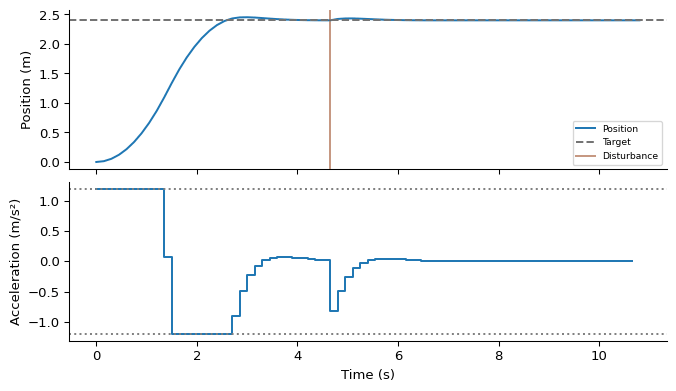

In [2]:
dt = 0.15
target = np.array([2.4, 0.0])
x = np.array([0.0, 0.0])
states = [x.copy()]
actions = []
for step in range(72):
    u = mpc_inputs(x, target, dt=dt, limit=1.2)[0]
    x = x + np.array([dt * x[1] + 0.5 * dt * dt * u, dt * u])
    if step == 30:
        x[1] += 0.22
    actions.append(u)
    states.append(x.copy())
x = np.asarray(states)
t = np.arange(len(x)) * dt
u = np.array(actions)
print(
    f"Final position error {abs(x[-1,0]-target[0]):.4g} m | final speed {x[-1,1]:.4g} m/s | maximum effort {abs(u).max():.4f} m/s²"
)
print("Stationary baseline final position error (m)", target[0])
assert abs(u).max() <= 1.2 + 1e-8 and abs(x[-1, 0] - target[0]) < 0.02
fig, (a, b) = plt.subplots(2, 1, figsize=(7, 4), sharex=True, constrained_layout=True)
a.plot(t, x[:, 0], label="Position")
a.axhline(target[0], ls="--", color="0.45", label="Target")
a.axvline(31 * dt, color="sienna", alpha=0.6, label="Disturbance")
a.set(ylabel="Position (m)")
a.legend(fontsize=7)
b.step(t[:-1], u, where="post")
b.axhline(1.2, ls=":", color="0.5")
b.axhline(-1.2, ls=":", color="0.5")
b.set(xlabel="Time (s)", ylabel="Acceleration (m/s²)")
plt.show()

## Interpreting the result

A longer horizon lets the optimiser anticipate braking earlier. The only hard constraint in this exercise is the acceleration bound.

## Exercise

Halve the acceleration bound and compare settling time and maximum overshoot.

## References

[Rawlings, Mayne and Diehl, Model Predictive Control](https://sites.engineering.ucsb.edu/~jbraw/mpc/)

[OSQP, model predictive control example](https://osqp.org/docs/examples/mpc.html)